# 02 · Why did life expectancy change?

Notebook 01 showed **what** happened. This notebook asks **why**, in three layers, each one closer to something a health system can act on:

| Question | Method | What it tells us |
|---|---|---|
| **At which ages** did death rates fall (or rise)? | Life-table **decomposition** (Arriaga method) | Splits each change in life expectancy into exact contributions from infants, children, young adults, middle age and old age |
| **What kills people** at those ages, and how has it changed? | Trends in cause-related mortality (child, maternal, HIV, TB, malaria, NCDs, injuries) | Links the age pattern to specific diseases and risks |
| **What conditions** go with improvement? | Two-way **fixed-effects** panel regression | Within-country associations between change in health/economic factors and change in life expectancy, net of global trends |

### Why this framing
Life expectancy is not measured directly. It's a **summary of death rates at every age in one year**. So any change in life expectancy *must* come from changes in death rates at specific ages. That makes the age decomposition the most rigorous first step in explaining it: it isn't a model or an estimate, it's an exact accounting identity.

### Context from WHO and UNICEF
- WHO's *World Health Statistics 2025* reports that global life expectancy fell by 1.8 years between 2019 and 2021, the largest drop in recent history, and that NCDs now cause most deaths before age 70 worldwide.
- Maternal deaths fell by over 40% and under-5 deaths more than halved between 2000 and 2023, but WHO warns progress has stalled.
- UNICEF/UN IGME report 4.9 million under-5 deaths in 2024, nearly half of them newborns, with 58% in sub-Saharan Africa. Malaria is the largest single killer of children aged 1-59 months, and the pace of reduction has slowed by more than 60% since 2015.

Sources: [WHO, World Health Statistics 2025 news release](https://www.who.int/news/item/15-05-2025-who-warns-of-slowing-global-health-gains-in-new-statistics-report) · [UNICEF, child mortality 2024](https://www.unicef.org/press-releases/progress-reducing-child-deaths-slows-49-million-children-under-five-die-2024)

Your job in this notebook is to test whether **the data** shows these patterns, where, and how strongly.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import PANEL_PATH, FIGURES_DIR, AGE_BANDS
from src.plotting import set_style, stacked_contributions, REGION_COLORS, SEX_COLORS, PALETTE, INK, INK_SECONDARY, SURFACE
from src.analysis import (weighted_mean, regional_series, load_life_tables, table_for, decompose,
                          decompose_all, regional_decomposition, fixed_effects_drivers)

set_style()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140, "display.precision", 2)

panel = pd.read_csv(PANEL_PATH)
lt = load_life_tables()
if lt is None:
    raise FileNotFoundError("No life tables found. Re-run `python -m src.fetch_data` and `python -m src.build_dataset`.")

FOCUS_COUNTRY = "KEN"      # any ISO3 code
FOCUS_REGION = "Africa"    # any WHO region name
if FOCUS_COUNTRY not in set(lt["iso3"]):
    FOCUS_COUNTRY = lt.loc[lt["iso3"].isin(panel.loc[panel["who_region"] == FOCUS_REGION, "iso3"]), "iso3"].iloc[0]
    print(f"Focus country not in life tables; using {FOCUS_COUNTRY}")

BANDS = [label for _, _, label in AGE_BANDS]
LT_YEARS = sorted(lt["year"].unique())
START = LT_YEARS[0]
PRE_COVID = 2019 if 2019 in LT_YEARS else max(y for y in LT_YEARS if y < 2020)
LATEST = LT_YEARS[-1]
REGION_ORDER = [r for r in REGION_COLORS if r in set(panel["who_region"])]

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png")

print(f"Life tables: {lt['iso3'].nunique()} countries, {START}-{LATEST}. Periods: gains {START}-{PRE_COVID}, COVID {PRE_COVID}-{LATEST}")

Life tables: 185 countries, 2000-2023. Periods: gains 2000-2019, COVID 2019-2023


## 1. Check the life tables before trusting them

If our life-table code is right, life expectancy computed from WHO's death rates should match WHO's published life expectancy almost exactly. Small differences (a few hundredths of a year) come from different assumptions about the timing of deaths within each age group. Large differences would mean a bug or a data problem.

In [2]:
check = []
for year in [START, PRE_COVID, LATEST]:
    for iso in lt.loc[lt["year"] == year, "iso3"].unique():
        try:
            ours = table_for(lt, iso, year, "both")["ex"].iloc[0]
        except KeyError:
            continue
        check.append({"iso3": iso, "year": year, "computed": ours})
check = pd.DataFrame(check).merge(panel[panel["sex"] == "both"][["iso3", "year", "life_expectancy"]], on=["iso3", "year"])
check["diff"] = check["computed"] - check["life_expectancy"]

print(f"Compared {len(check)} country-years. Mean absolute difference: {check['diff'].abs().mean():.3f} years; "
      f"largest: {check['diff'].abs().max():.2f} years")
print("Worst matches:"); print(check.reindex(check["diff"].abs().sort_values(ascending=False).index).head(5).to_string(index=False))

Compared 555 country-years. Mean absolute difference: 0.148 years; largest: 1.53 years
Worst matches:
iso3  year  computed  life_expectancy  diff
 KWT  2019     84.83             83.3  1.53
 PRI  2019     80.02             78.9  1.12
 THA  2019     79.25             78.2  1.05
 KOR  2019     84.71             83.7  1.01
 CHL  2019     82.30             81.3  1.00


## 2. Where the gains came from: from the first year to the pre-COVID peak

Each bar splits a region's change in life expectancy into the contribution of each age group. Bars to the right of zero are years **gained** because death rates at those ages fell. The black tick is the net change.

Regional figures are population-weighted averages of country decompositions.

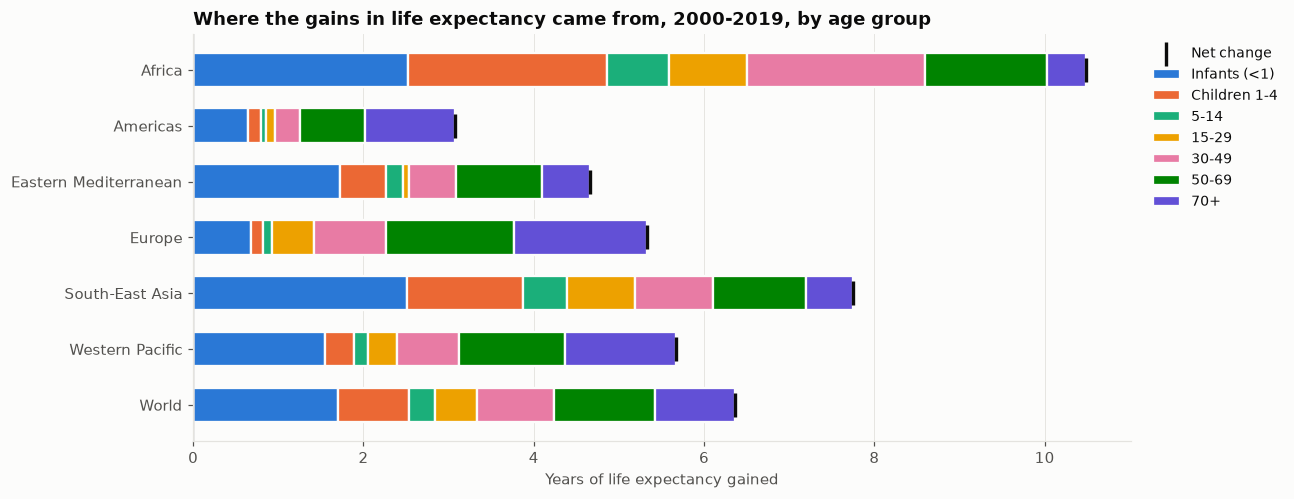

Africa: +10.5 years. Under-5s +4.9 (46%), ages 15-49 +3.0 (29%), 50+ +1.9 (18%). Largest single band: Infants (<1).
Americas: +3.1 years. Under-5s +0.8 (26%), ages 15-49 +0.4 (13%), 50+ +1.8 (59%). Largest single band: 70+.
Eastern Mediterranean: +4.7 years. Under-5s +2.3 (49%), ages 15-49 +0.6 (13%), 50+ +1.6 (34%). Largest single band: Infants (<1).
Europe: +5.3 years. Under-5s +0.8 (15%), ages 15-49 +1.3 (25%), 50+ +3.1 (57%). Largest single band: 70+.
South-East Asia: +7.7 years. Under-5s +3.9 (50%), ages 15-49 +1.7 (22%), 50+ +1.6 (21%). Largest single band: Infants (<1).
Western Pacific: +5.7 years. Under-5s +1.9 (33%), ages 15-49 +1.1 (19%), 50+ +2.5 (45%). Largest single band: Infants (<1).
World: +6.4 years. Under-5s +2.5 (40%), ages 15-49 +1.4 (22%), 50+ +2.1 (33%). Largest single band: Infants (<1).


In [3]:
gains = decompose_all(lt, panel, START, PRE_COVID, "both")
gains_regional = regional_decomposition(gains, BANDS).reindex(REGION_ORDER + ["World"])

fig, ax = plt.subplots(figsize=(11, 4.8))
stacked_contributions(ax, gains_regional[BANDS])
ax.invert_yaxis()
ax.set_title(f"Where the gains in life expectancy came from, {START}-{PRE_COVID}, by age group")
ax.set_xlabel("Years of life expectancy gained")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
save(fig, "10_decomposition_gains")
plt.show()

def describe_decomposition(row, label):
    total = row["total"]
    under5 = row["Infants (<1)"] + row["Children 1-4"]
    young_adult = row["15-29"] + row["30-49"]
    older = row["50-69"] + row["70+"]
    top = row[BANDS].idxmax()
    return (f"{label}: {total:+.1f} years. Under-5s {under5:+.1f} ({under5 / total:.0%}), "
            f"ages 15-49 {young_adult:+.1f} ({young_adult / total:.0%}), 50+ {older:+.1f} ({older / total:.0%}). "
            f"Largest single band: {top}.")

for region, row in gains_regional.iterrows():
    print(describe_decomposition(row, region))

### How to read this

The age pattern is a fingerprint of the causes behind it:

- **Large gains at ages 0-4** point to falling infant and child deaths: vaccination, malaria prevention and treatment, better newborn care, clean water and sanitation, and nutrition.
- **Large gains at ages 15-49**, especially in Africa, usually reflect the **HIV/AIDS response**. Antiretroviral therapy was scaled up from the mid-2000s and sharply cut deaths among young adults. Lower maternal mortality also shows up here for women.
- **Gains at 50+** come from lower deaths from **cardiovascular disease, cancers and other NCDs**, typically through tobacco control, treatment of high blood pressure and better hospital care. This is the main source of gains in richer regions, where child deaths are already low.

When you write up your results, connect each region's pattern to these explanations, and check them against the cause-related indicators in section 5.

## 3. Women and men: did they gain in the same ways?

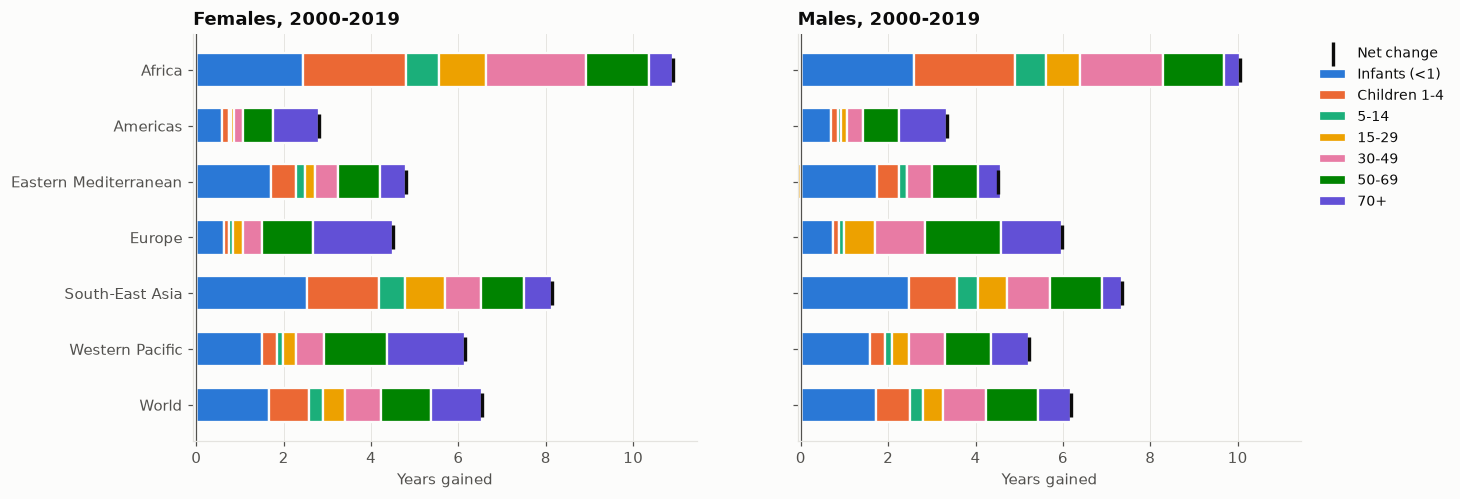

,female gain,male gain,women gained more by,band driving the difference
who_region,,,,
Africa,10.91,10.05,0.86,30-49
Americas,2.81,3.34,-0.54,30-49
Eastern Mediterranean,4.81,4.52,0.29,15-29
Europe,4.51,5.98,-1.47,30-49
South-East Asia,8.13,7.36,0.78,Children 1-4
Western Pacific,6.16,5.23,0.92,70+
World,6.53,6.19,0.34,70+


In [4]:
by_sex = {}
for sex in ["female", "male"]:
    d = decompose_all(lt, panel, START, PRE_COVID, sex)
    by_sex[sex] = regional_decomposition(d, BANDS).reindex(REGION_ORDER + ["World"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True, sharex=True)
for ax, sex in zip(axes, ["female", "male"]):
    stacked_contributions(ax, by_sex[sex][BANDS])
    ax.set_title(f"{sex.capitalize()}s, {START}-{PRE_COVID}")
    ax.set_xlabel("Years gained")
axes[0].invert_yaxis()
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
save(fig, "11_decomposition_by_sex")
plt.show()

compare = pd.DataFrame({"female gain": by_sex["female"]["total"], "male gain": by_sex["male"]["total"]})
compare["women gained more by"] = compare["female gain"] - compare["male gain"]
diff_bands = by_sex["female"][BANDS] - by_sex["male"][BANDS]
compare["band driving the difference"] = diff_bands.abs().idxmax(axis=1)
compare

**What to look for:** if men gained more in middle age, the sex gap is narrowing (common where male smoking and cardiovascular deaths have fallen). If women gained more at 15-49, falling maternal mortality and HIV treatment (women in Africa have higher HIV prevalence and were often reached first by treatment programmes) are likely contributors.

## 4. What COVID-19 took away

The same decomposition applied to the pre-COVID year and the latest year. Here the bars should mostly point **left**: years lost, and at which ages.

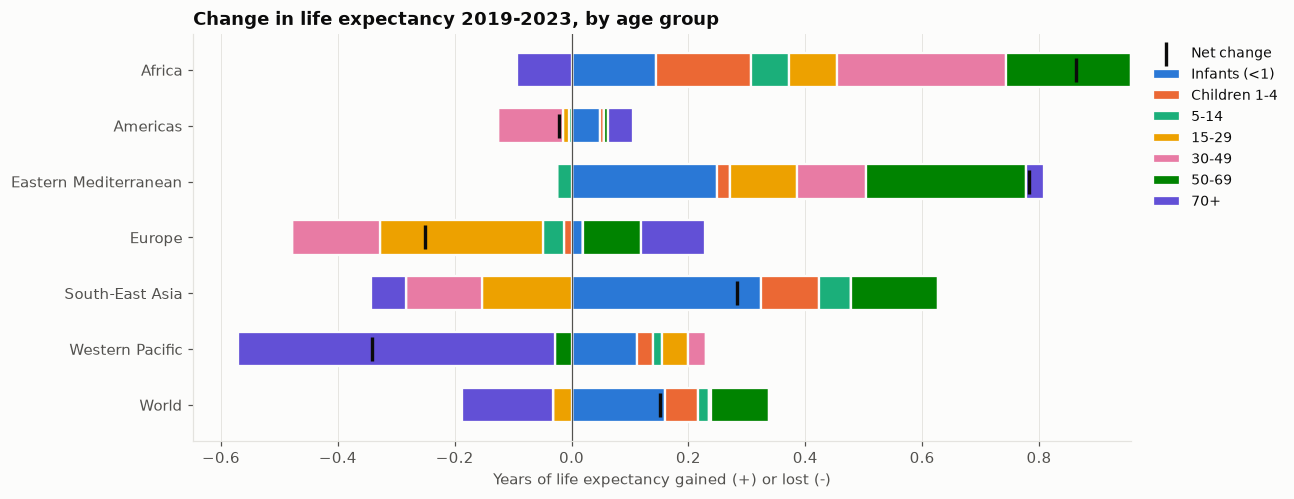

Africa: +0.86 years; ages 50+ account for +0.12
Americas: -0.02 years; ages 50+ account for +0.05
Eastern Mediterranean: +0.78 years; ages 50+ account for +0.30
Europe: -0.25 years; ages 50+ account for +0.21
South-East Asia: +0.28 years; ages 50+ account for +0.09
Western Pacific: -0.34 years; ages 50+ account for -0.57
World: +0.15 years; ages 50+ account for -0.06

Largest losses:
                country             who_region  total
PSE  West Bank and Gaza  Eastern Mediterranean -13.83
LBY               Libya  Eastern Mediterranean  -4.41
GUY              Guyana               Americas  -3.84
TUR             Turkiye                 Europe  -2.13
KWT              Kuwait  Eastern Mediterranean  -1.94
MNE          Montenegro                 Europe  -1.61
SDN               Sudan  Eastern Mediterranean  -1.57
GRD             Grenada               Americas  -1.50
LCA           St. Lucia               Americas  -1.49
UKR             Ukraine                 Europe  -1.42


In [5]:
if LATEST > PRE_COVID:
    covid = decompose_all(lt, panel, PRE_COVID, LATEST, "both")
    covid_regional = regional_decomposition(covid, BANDS).reindex(REGION_ORDER + ["World"])

    fig, ax = plt.subplots(figsize=(11, 4.8))
    stacked_contributions(ax, covid_regional[BANDS])
    ax.invert_yaxis()
    ax.set_title(f"Change in life expectancy {PRE_COVID}-{LATEST}, by age group")
    ax.set_xlabel("Years of life expectancy gained (+) or lost (-)")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
    save(fig, "12_decomposition_covid")
    plt.show()

    for region, row in covid_regional.iterrows():
        older = row["50-69"] + row["70+"]
        print(f"{region}: {row['total']:+.2f} years; ages 50+ account for {older:+.2f}")
    worst = covid.sort_values("total").head(10)[["country", "who_region", "total"]]
    print("\nLargest losses:"); print(worst.round(2).to_string())
else:
    print("Life tables don't extend past the pre-COVID year, so this section is skipped.")

**How to read this:** COVID-19 deaths were concentrated at older ages, so losses should sit mainly in the 50-69 and 70+ bands. Losses at younger ages can point to disrupted health services (missed vaccinations, untreated malaria or HIV) rather than the virus itself. Note: for countries without good death registration, WHO's 2020-2021 figures rely on modelled excess mortality, so treat them as estimates with wide uncertainty.

## 5. One country over time: when did the change happen?

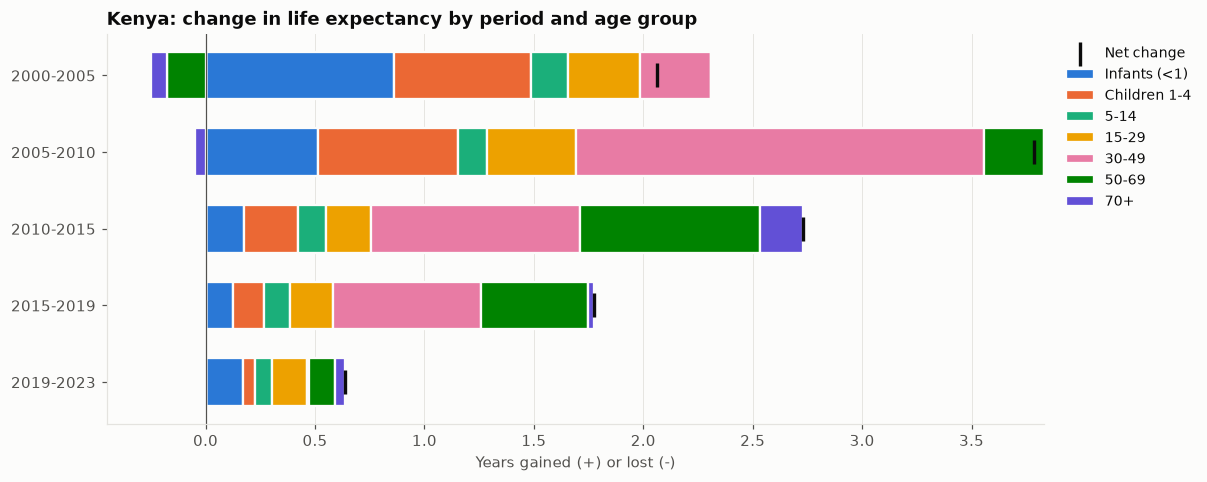

,Infants (<1),Children 1-4,5-14,15-29,30-49,50-69,70+,total
2000-2005,0.86,0.63,0.17,0.33,0.33,-0.18,-0.07,2.06
2005-2010,0.51,0.64,0.13,0.41,1.86,0.28,-0.05,3.78
2010-2015,0.18,0.25,0.13,0.20,0.96,0.83,0.20,2.73
2015-2019,0.13,0.14,0.11,0.20,0.68,0.49,0.03,1.77
2019-2023,0.17,0.06,0.08,0.16,0.01,0.12,0.05,0.64


In [6]:
periods = [y for y in LT_YEARS if (y - START) % 5 == 0 and y <= PRE_COVID]
if PRE_COVID not in periods:
    periods.append(PRE_COVID)
if LATEST > PRE_COVID:
    periods.append(LATEST)
timeline = pd.DataFrame({f"{a}-{b}": decompose(lt, FOCUS_COUNTRY, a, b, "both") for a, b in zip(periods[:-1], periods[1:])}).T
country_name = panel.loc[panel["iso3"] == FOCUS_COUNTRY, "country"].iloc[0]

fig, ax = plt.subplots(figsize=(11, 0.6 * len(timeline) + 1.6))
stacked_contributions(ax, timeline[BANDS])
ax.invert_yaxis()
ax.set_title(f"{country_name}: change in life expectancy by period and age group")
ax.set_xlabel("Years gained (+) or lost (-)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
save(fig, f"13_{FOCUS_COUNTRY}_timeline")
plt.show()

timeline["total"] = timeline.sum(axis=1)
timeline.round(2)

**Questions to answer for your focus country:** In which period was progress fastest, and which ages drove it? Did progress slow after 2015 (as UNICEF reports for child mortality globally)? Can you link turning points to known events, for example national HIV treatment scale-up, introduction of new vaccines (pneumococcal, rotavirus), malaria net campaigns or health financing reforms? Look these up and cite them; that's what turns a chart into an analysis.

## 6. What is killing people at those ages?

The decomposition tells us *which ages*. These indicators tell us *which causes*. Each panel shows the population-weighted regional average over time.

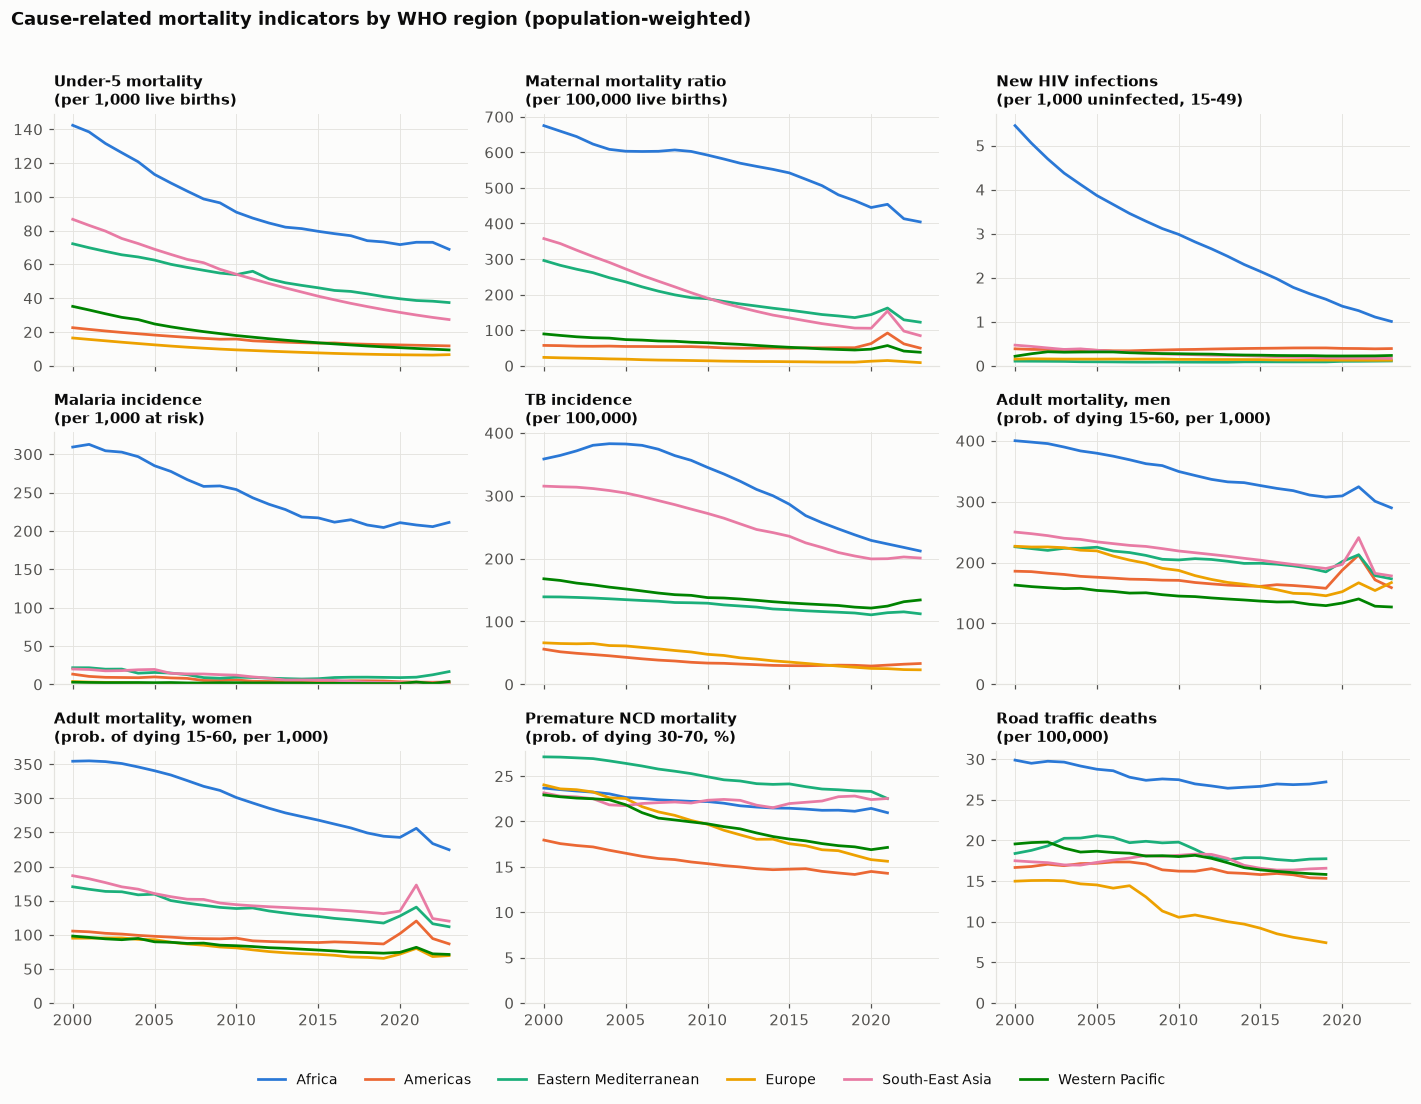

In [7]:
MORTALITY = {
    "u5_mortality": "Under-5 mortality\n(per 1,000 live births)",
    "maternal_mortality_ratio": "Maternal mortality ratio\n(per 100,000 live births)",
    "hiv_incidence": "New HIV infections\n(per 1,000 uninfected, 15-49)",
    "malaria_incidence": "Malaria incidence\n(per 1,000 at risk)",
    "tb_incidence": "TB incidence\n(per 100,000)",
    "adult_mortality_male": "Adult mortality, men\n(prob. of dying 15-60, per 1,000)",
    "adult_mortality_female": "Adult mortality, women\n(prob. of dying 15-60, per 1,000)",
    "ncd_mortality_30_70": "Premature NCD mortality\n(prob. of dying 30-70, %)",
    "road_traffic_deaths": "Road traffic deaths\n(per 100,000)",
}
MORTALITY = {k: v for k, v in MORTALITY.items() if k in panel and panel[k].notna().any()}

ncols = 3
nrows = int(np.ceil(len(MORTALITY) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.3 * nrows), sharex=True)
for ax, (col, title) in zip(axes.flat, MORTALITY.items()):
    s = regional_series(panel, col)
    for region in REGION_ORDER:
        d = s[s["who_region"] == region]
        ax.plot(d["year"], d[col], color=REGION_COLORS[region], label=region, linewidth=1.8)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(bottom=0)
for ax in list(axes.flat)[len(MORTALITY):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(REGION_ORDER), bbox_to_anchor=(0.5, -0.02), fontsize=9)
fig.suptitle("Cause-related mortality indicators by WHO region (population-weighted)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.03, 1, 0.97))
save(fig, "14_mortality_indicators")
plt.show()

In [8]:
# Percentage change from the first to the latest available year, by region
def pct_change_table(cols):
    rows = {}
    for col in cols:
        s = regional_series(panel, col)
        first_year = s["year"].min()
        last_year = s.groupby("year")["who_region"].nunique().loc[lambda x: x == x.max()].index.max()
        a = s[s["year"] == first_year].set_index("who_region")[col]
        b = s[s["year"] == last_year].set_index("who_region")[col]
        rows[f"{col} ({first_year}-{last_year})"] = (b / a - 1) * 100
    return pd.DataFrame(rows).T.reindex(columns=REGION_ORDER).round(0)

changes = pct_change_table(MORTALITY)
print("% change in each indicator (negative = improvement):")
changes

% change in each indicator (negative = improvement):


who_region,Africa,Americas,Eastern Mediterranean,Europe,South-East Asia,Western Pacific
u5_mortality (2000-2023),-52.0,-48.0,-48.0,-60.0,-68.0,-73.0
maternal_mortality_ratio (2000-2023),-40.0,-13.0,-59.0,-62.0,-76.0,-58.0
hiv_incidence (2000-2023),-82.0,1.0,3.0,-18.0,-64.0,8.0
malaria_incidence (2000-2023),-32.0,-76.0,-23.0,-100.0,-91.0,32.0
tb_incidence (2000-2023),-41.0,-41.0,-19.0,-65.0,-36.0,-20.0
adult_mortality_male (2000-2023),-28.0,-15.0,-23.0,-26.0,-29.0,-22.0
adult_mortality_female (2000-2023),-37.0,-18.0,-34.0,-27.0,-36.0,-27.0
ncd_mortality_30_70 (2000-2021),-11.0,-20.0,-17.0,-35.0,-3.0,-25.0
road_traffic_deaths (2000-2019),-9.0,-8.0,-4.0,-51.0,-5.0,-19.0


**What to look for:** Which risks fell fastest in each region, and do they line up with the age bands that drove gains in section 2? For example, if Africa's gains came largely from ages 15-49, HIV incidence and adult mortality should show steep declines. Also look for **stalls or reversals**, such as malaria, which WHO says has been resurging since 2015, or road traffic deaths, which often rise with motorisation.

### The epidemiological transition

As countries develop, deaths shift from infections, maternal and newborn conditions to NCDs. This shift shapes what prevention should focus on.

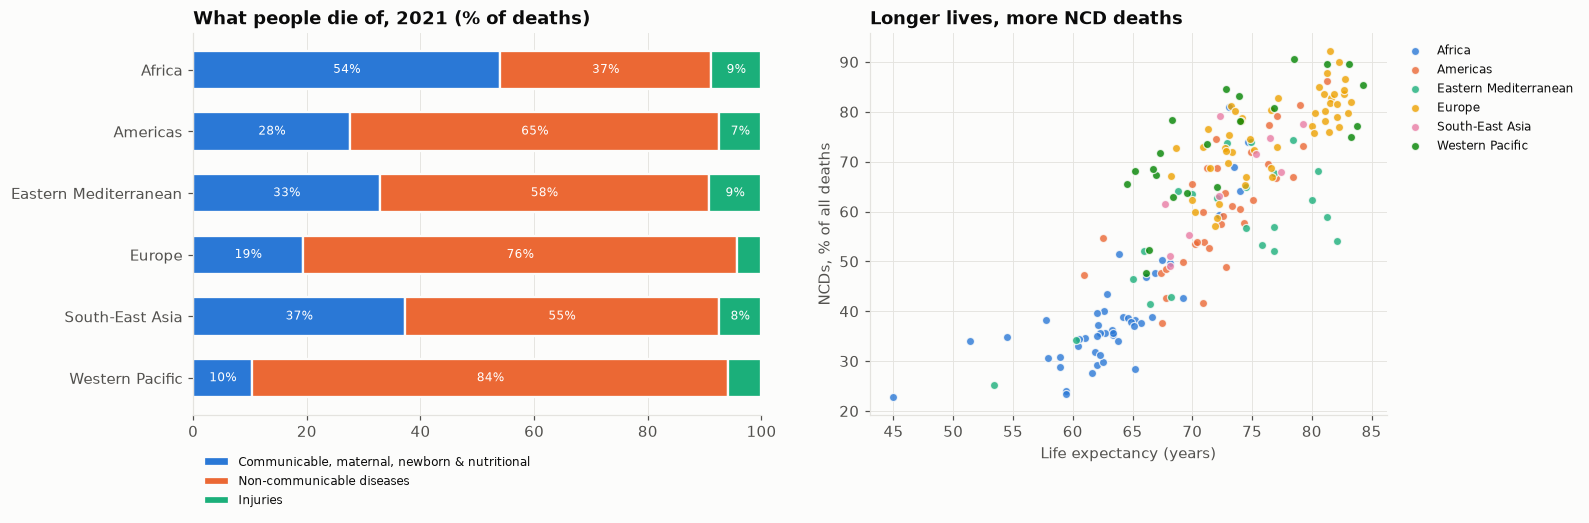

In [9]:
cause_cols = ["deaths_communicable_pct", "deaths_ncd_pct", "deaths_injury_pct"]
if all(c in panel and panel[c].notna().any() for c in cause_cols):
    both_ = panel[panel["sex"] == "both"]
    cause_year = int(both_.dropna(subset=cause_cols)["year"].max())
    snap = both_[both_["year"] == cause_year]
    mix = pd.DataFrame({c: snap.groupby("who_region").apply(lambda g: weighted_mean(g, c), include_groups=False) for c in cause_cols})
    mix = mix.div(mix.sum(axis=1), axis=0).mul(100).reindex(REGION_ORDER).dropna()
    labels = {"deaths_communicable_pct": "Communicable, maternal, newborn & nutritional",
              "deaths_ncd_pct": "Non-communicable diseases", "deaths_injury_pct": "Injuries"}

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.1, 1]})
    left = np.zeros(len(mix))
    for i, c in enumerate(cause_cols):
        axes[0].barh(mix.index, mix[c], left=left, color=PALETTE[i], height=0.62, edgecolor=SURFACE, linewidth=1.5, label=labels[c])
        for y, (l, v) in enumerate(zip(left, mix[c])):
            if v > 7:
                axes[0].annotate(f"{v:.0f}%", xy=(l + v / 2, y), ha="center", va="center", fontsize=8, color="white")
        left += mix[c].to_numpy()
    axes[0].invert_yaxis(); axes[0].grid(axis="y", visible=False); axes[0].set_xlim(0, 100)
    axes[0].set_title(f"What people die of, {cause_year} (% of deaths)")
    axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=1, fontsize=8)

    for region in REGION_ORDER:
        d = snap[snap["who_region"] == region]
        axes[1].scatter(d["life_expectancy"], d["deaths_ncd_pct"], color=REGION_COLORS[region], s=28, alpha=0.8,
                        edgecolor=SURFACE, linewidth=0.8, label=region)
    axes[1].set_xlabel("Life expectancy (years)"); axes[1].set_ylabel("NCDs, % of all deaths")
    axes[1].set_title("Longer lives, more NCD deaths")
    axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    save(fig, "15_cause_mix")
    plt.show()
else:
    print("Cause-of-death shares not available; skipping.")

## 7. What conditions go with improvement? A fixed-effects model

Notebook 01 showed simple correlations. Those mostly compare rich countries with poor ones, so almost everything looks important because it moves with income.

A **two-way fixed-effects model** asks a sharper question: *within the same country*, in years when (say) vaccination coverage was higher than that country's usual level, was life expectancy also higher, beyond the worldwide trend that year? Country effects remove everything stable about a country (geography, history, institutions); year effects remove global shocks and trends.

Coefficients are in **years of life expectancy per one standard deviation** of each factor, so they can be compared. Lines show 95% confidence intervals with standard errors clustered by country.

Fixed-effects model: 1,767 country-years, 128 countries, R² 0.98


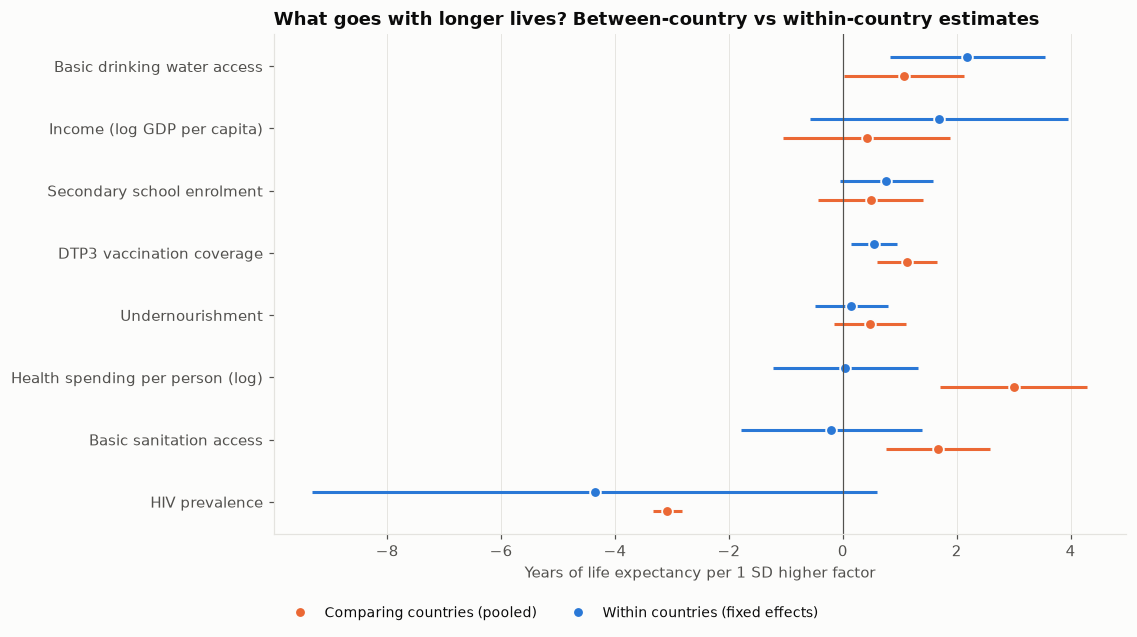

C:\Users\linet\AppData\Local\Temp\ipykernel_6204\3460892154.py:37: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  result = fe.join(pooled, rsuffix="_pooled")[["coef", "low", "high", "p", "coef_pooled"]]


,coef,low,high,p,coef_pooled
HIV prevalence,-4.36,-9.31,0.59,8.45e-02,-3.08
Basic sanitation access,-0.20,-1.79,1.38,8.03e-01,1.68
Health spending per person (log),0.05,-1.23,1.32,9.43e-01,3.00
Undernourishment,0.15,-0.50,0.80,6.47e-01,0.48
DTP3 vaccination coverage,0.55,0.14,0.96,7.81e-03,1.13
Secondary school enrolment,0.77,-0.04,1.58,6.37e-02,0.49
Income (log GDP per capita),1.69,-0.58,3.96,1.44e-01,0.42
Basic drinking water access,2.18,0.82,3.54,1.64e-03,1.08


In [10]:
panel["log_health_exp_pc"] = np.log(panel["health_exp_pc_usd"].where(panel["health_exp_pc_usd"] > 0))
FACTORS = {
    "log_gdp_pc_ppp": "Income (log GDP per capita)",
    "log_health_exp_pc": "Health spending per person (log)",
    "dtp3_coverage": "DTP3 vaccination coverage",
    "hiv_prevalence": "HIV prevalence",
    "basic_water": "Basic drinking water access",
    "basic_sanitation": "Basic sanitation access",
    "secondary_enrollment": "Secondary school enrolment",
    "undernourishment": "Undernourishment",
}
FACTORS = {k: v for k, v in FACTORS.items() if k in panel and panel[k].notna().mean() > 0.3}

# Pre-COVID years only, so the 2020-21 shock doesn't dominate
model_data = panel[panel["year"] <= PRE_COVID]
fe = fixed_effects_drivers(model_data, "life_expectancy", list(FACTORS), country_effects=True)
pooled = fixed_effects_drivers(model_data, "life_expectancy", list(FACTORS), country_effects=False)
print(f"Fixed-effects model: {fe.attrs['n_obs']:,} country-years, {fe.attrs['n_countries']} countries, R² {fe.attrs['r2']:.2f}")

fig, ax = plt.subplots(figsize=(10, 0.55 * len(FACTORS) + 1.5))
order = fe["coef"].sort_values().index
y = np.arange(len(order))
for offset, (table, label, color) in zip([-0.15, 0.15], [(pooled, "Comparing countries (pooled)", PALETTE[1]),
                                                        (fe, "Within countries (fixed effects)", PALETTE[0])]):
    t = table.loc[order]
    ax.hlines(y + offset, t["low"], t["high"], color=color, linewidth=2)
    ax.plot(t["coef"], y + offset, "o", color=color, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.2, label=label)
ax.axvline(0, color=INK_SECONDARY, linewidth=0.8)
ax.set_yticks(y, [FACTORS[f] for f in order])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Years of life expectancy per 1 SD higher factor")
ax.set_title("What goes with longer lives? Between-country vs within-country estimates")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2, fontsize=9)
save(fig, "16_drivers_fixed_effects")
plt.show()

result = fe.join(pooled, rsuffix="_pooled")[["coef", "low", "high", "p", "coef_pooled"]]
result.index = [FACTORS[f] for f in result.index]
result.sort_values("coef")

### How to interpret this honestly

- **Where the two estimates differ a lot**, the pooled one was mostly picking up differences between rich and poor countries (confounding). The fixed-effects estimate is the more credible one.
- **A significant within-country association still isn't proof of cause.** Reverse causation (healthier populations get richer), other policies changing at the same time, and measurement error all remain possible. Say "associated with", not "causes".
- **Many World Bank indicators are themselves modelled and smoothed**, which tends to shrink within-country estimates towards zero. A factor that looks unimportant here may still matter.
- **Factors overlap.** Water and sanitation, or income and health spending, rise together; their individual coefficients are less stable than their combined effect.
- Good next steps: lag the factors by a few years (vaccines and treatment act with delay), estimate separately by region, and compare with published evidence.

## 8. Summary of findings (generated from your data)

In [11]:
world = gains_regional.loc["World"]
lines = []
lines.append(f"- Between {START} and {PRE_COVID}, life expectancy rose by {world['total']:.1f} years on average "
             f"(population-weighted across countries). Under-5s contributed {(world['Infants (<1)'] + world['Children 1-4']) / world['total']:.0%} of this gain.")
reg = gains_regional.drop("World")
best = reg["total"].idxmax()
lines.append(f"- The largest gain was in {best} ({reg.loc[best, 'total']:+.1f} years), where the biggest contribution came from ages {reg.loc[best, BANDS].idxmax()}.")
for region, row in reg.iterrows():
    main = row[BANDS].idxmax()
    lines.append(f"  - {region}: {row['total']:+.1f} years, led by {main} ({row[main] / row['total']:.0%} of the gain).")
if LATEST > PRE_COVID:
    w = covid_regional.loc["World"]
    hardest = covid_regional.drop("World")["total"].idxmin()
    lines.append(f"- From {PRE_COVID} to {LATEST}, life expectancy changed by {w['total']:+.2f} years on average, "
                 f"with ages 50+ accounting for {(w['50-69'] + w['70+']):+.2f}. {hardest} was hit hardest ({covid_regional.loc[hardest, 'total']:+.2f}).")
fe_sig = fe[fe["p"] < 0.05].sort_values("coef", key=abs, ascending=False)
if len(fe_sig):
    top = ", ".join(f"{FACTORS[f].lower()} ({c:+.2f})" for f, c in fe_sig["coef"].head(3).items())
    lines.append(f"- Within countries, the factors most strongly associated with life expectancy were: {top} years per SD.")
print("\n".join(lines))

- Between 2000 and 2019, life expectancy rose by 6.4 years on average (population-weighted across countries). Under-5s contributed 40% of this gain.
- The largest gain was in Africa (+10.5 years), where the biggest contribution came from ages Infants (<1).
  - Africa: +10.5 years, led by Infants (<1) (24% of the gain).
  - Americas: +3.1 years, led by 70+ (34% of the gain).
  - Eastern Mediterranean: +4.7 years, led by Infants (<1) (37% of the gain).
  - Europe: +5.3 years, led by 70+ (29% of the gain).
  - South-East Asia: +7.7 years, led by Infants (<1) (32% of the gain).
  - Western Pacific: +5.7 years, led by Infants (<1) (27% of the gain).
- From 2019 to 2023, life expectancy changed by +0.15 years on average, with ages 50+ accounting for -0.06. Western Pacific was hit hardest (-0.34).
- Within countries, the factors most strongly associated with life expectancy were: basic drinking water access (+2.18), dtp3 vaccination coverage (+0.55) years per SD.


Copy the summary above into your README's **Key findings**, then add the *why*: for each finding, one sentence linking it to known causes and programmes (with a citation). For example: *"In Africa, X% of the gain came from ages 15-49, consistent with the expansion of antiretroviral therapy from the mid-2000s; HIV incidence in the region fell by Y% over the same period."*

**Next:** notebook 03 forecasts life expectancy to 2030, and notebook 04 estimates how many years of life could be gained by meeting the SDG health targets.